# Diagnóstico de aprendizagem e lacunas por questionário

## Problema
Professores do Ensino Fundamental I (1º ao 5º ano) não têm um jeito rápido e
padronizado de saber **em quais conteúdos** cada aluno está abaixo do esperado
para a sua série, nem **o que fazer** a respeito.

## Referências
- **BNCC:** define o que se espera que o aluno aprenda em cada ano.
- **SAEB:** avalia Língua Portuguesa e Matemática; por isso o projeto começa por essas duas disciplinas.
- **Compromisso Nacional Criança Alfabetizada (MEC):** a leitura nos anos iniciais continua sendo um dos conteúdos avaliados.

## Quem se beneficia
- **O aluno**, que recebe reforço no conteúdo certo antes de acumular atraso.
- **O professor**, que sabe o que reforçar com cada aluno e com a turma.

## O que a IA faz
1. O aluno responde a um questionário da sua série: **2 disciplinas × 4 conteúdos × 3 questões**.
2. O sistema corrige as respostas e conta os acertos em cada conteúdo.
3. Um modelo de Machine Learning estima, **para cada conteúdo**, a probabilidade de
   haver uma **lacuna** (desempenho abaixo do esperado para a série).
   Trata-se de uma classificação **multirrótulo**: um aluno pode ter nenhuma, uma ou várias lacunas.
4. A partir das lacunas, o sistema gera os **insights**:
   - o **nível em cada disciplina**;
   - os **conteúdos a reforçar**, do mais urgente ao menos urgente;
   - uma **estratégia de estudo** para cada conteúdo, tirada de um catálogo fixo e revisável.

```
respostas ──► validar ──► corrigir ──► 13 features ──► modelo ──► 8 probabilidades
 (série +      (inválido    (acertos       (acertos +      (regressão     de lacuna
  24 letras)    para aqui)   por conteúdo)  série)          logística)        │
                                                                              ▼
     insights ◄── nível por disciplina + conteúdos a reforçar ◄── lacuna / sem_lacuna / a_confirmar
```

Por que o modelo e não só uma regra pelos acertos (como "errou alguma questão do conteúdo")?
Com apenas 3 questões, um chute certo ou um erro de distração mudam o resultado. O modelo usa
também o desempenho nos **outros** conteúdos e a **série** para decidir com mais segurança.
O ganho sobre a melhor regra desse tipo é medido nos passos 9 e 13.

## Conceitos básicos
- **Machine Learning supervisionado:** o modelo aprende a partir de exemplos já rotulados
  (aqui, alunos cujas lacunas o professor já avaliou) e depois prevê o rótulo de alunos novos.
- **Feature:** cada informação de entrada do modelo (aqui, os acertos em cada conteúdo e a série).
- **Rótulo (ou alvo):** o que se quer prever (aqui, lacuna sim/não em cada conteúdo).
- **Classificação binária × multirrótulo:** binária é responder uma pergunta sim/não; multirrótulo
  é responder várias perguntas sim/não ao mesmo tempo para o mesmo aluno (8, uma por conteúdo).
- **Treino e teste:** o modelo aprende com uma parte dos dados (treino) e é avaliado numa parte que
  nunca viu (teste), para medir como ele se sairia com alunos novos.

## Qual erro é o mais grave
**Não detectar uma lacuna que existe:** o aluno ficaria sem o reforço de que precisa.
Apontar uma lacuna que não existe custa menos: uma atividade extra de revisão.

**Métricas** (calculadas por conteúdo e depois com média entre os 8 conteúdos):
- **Prioritária:** recall de lacuna (de todas as lacunas reais, quantas o modelo encontra).
- **De equilíbrio:** F1-macro. Impede que o modelo "ganhe" no recall simplesmente
  apontando lacuna em tudo.

## Uso responsável
- O resultado é uma **triagem**: apoia o professor, não substitui a avaliação dele.
- Questionários inválidos **não recebem diagnóstico**, e conteúdos com resultado
  duvidoso aparecem como **"a confirmar pelo professor"** (falhar fechado).
- As estratégias de estudo vêm de um **catálogo fixo**, não são geradas por IA no momento
  do uso: o texto pode ser revisado por pedagogos e o sistema funciona offline.
- Dados de crianças são sensíveis (LGPD, art. 14). Este projeto usa apenas **dados simulados**.

## ODS
- ODS 4 (Educação de qualidade)
- ODS 10 (Redução das desigualdades)

## Como executar
- **Python 3.11 ou superior** (exigência do pandas 3).
- Instale as dependências: `pip install -r requirements.txt` (de preferência dentro de um ambiente virtual, `python -m venv .venv`).
- Rode `Kernel → Restart & Run All`. As células dependem umas das outras e precisam rodar **em ordem**, de cima para baixo.
- A semente fixa (`SEED`) garante os mesmos resultados em qualquer execução.

**Arquivos gerados pelo notebook:**

| Arquivo | O que é |
|---|---|
| `data/questionarios.csv` | a base simulada (passo 5) |
| `models/modelo.onnx` | o modelo treinado, no formato que o Java lê (passo 16) |
| `models/modelo_info.json` | o contrato: tudo o que o Java precisa saber para usar o modelo (passo 17) |
| `integracao_java/golden_tests.csv` | casos de teste com as respostas esperadas, para conferir o Java (passo 17) |

## 1. Bibliotecas
Todos os imports ficam aqui, no topo, como recomenda a PEP 8 (guia de estilo do Python): quem abre o notebook vê de cara todas as dependências. Ordem: biblioteca padrão, depois bibliotecas de terceiros.

| Biblioteca | Para que serve no projeto |
|---|---|
| `json`, `pathlib` | gravar o contrato em JSON e montar caminhos de arquivos |
| `numpy` | contas com vetores e matrizes (a simulação inteira é feita com ele) |
| `pandas` | tabelas: ler e gravar CSV, filtrar, agrupar, calcular médias |
| `matplotlib` | gráficos da análise exploratória e da avaliação |
| `scikit-learn` | modelos, validação cruzada, busca de hiperparâmetros e métricas |
| `skl2onnx` | converter o modelo do scikit-learn para o formato ONNX |
| `onnxruntime` | executar o arquivo ONNX, para conferir que ele reproduz o modelo |

In [32]:
# ---- Biblioteca padrão do Python (já vem instalada) ----
# json: lê e grava arquivos JSON (texto chave-valor), usado no contrato com o Java (passo 17).
import json
# Path: representa caminhos de arquivos de forma independente do sistema operacional.
from pathlib import Path

# ---- Bibliotecas de terceiros (instaladas pelo requirements.txt) ----
# matplotlib.pyplot: desenha gráficos; "plt" é o apelido convencional.
import matplotlib.pyplot as plt
# numpy: vetores e matrizes numéricas com operações rápidas; "np" é o apelido convencional.
import numpy as np
# onnxruntime: executa modelos no formato ONNX, o mesmo motor que o Java usará.
import onnxruntime as ort
# pandas: tabelas (DataFrame) com colunas nomeadas, leitura e escrita de CSV; apelido "pd".
import pandas as pd
# to_onnx: converte um modelo do scikit-learn para o formato ONNX.
from skl2onnx import to_onnx
# FloatTensorType: descreve o tipo e o formato da entrada do modelo ONNX (float32, [N, 13]).
from skl2onnx.common.data_types import FloatTensorType
# clone: cria uma cópia "zerada" (sem treino) de um modelo, com os mesmos hiperparâmetros.
from sklearn.base import clone
# DummyClassifier: modelo "bobo" que ignora as features; serve de régua mínima (baseline).
from sklearn.dummy import DummyClassifier
# Dois modelos de árvores: Gradient Boosting (árvores em sequência) e Random Forest (árvores em paralelo).
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
# LogisticRegression: modelo linear que devolve probabilidades (o modelo escolhido no passo 10).
from sklearn.linear_model import LogisticRegression
# Métricas de avaliação: relatório por classe, F1, precisão e recall.
from sklearn.metrics import classification_report, f1_score, precision_score, recall_score
# Ferramentas de validação: busca em grade, divisão por grupos, previsões e avaliação por validação cruzada.
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold, cross_val_predict, cross_validate
# OneVsRestClassifier: treina um classificador binário por rótulo (aqui, um por conteúdo).
from sklearn.multiclass import OneVsRestClassifier
# make_pipeline: encadeia etapas (padronizar → classificar) num único objeto treinável.
from sklearn.pipeline import make_pipeline
# StandardScaler: padroniza cada feature para média 0 e desvio-padrão 1.
from sklearn.preprocessing import StandardScaler

## 2. Decisões do problema em código
As decisões do texto acima viram constantes: as séries atendidas, as disciplinas com os seus conteúdos (que definem as 8 saídas do modelo e a ordem delas), o valor que representa uma lacuna e a semente de reprodutibilidade.

**Conceitos usados:**
- **Constantes em MAIÚSCULAS:** convenção do Python (PEP 8) para valores que não devem mudar durante a execução.
- **Tupla × lista:** a tupla `( )` não pode ser alterada depois de criada; por isso é usada para dados fixos, como as séries.
- **Fonte única da verdade:** a tabela `CONTEUDOS_POR_DISCIPLINA` é escrita uma vez; `DISCIPLINAS`, `CONTEUDOS` e `DISCIPLINA_POR_CONTEUDO` são **derivados** dela. Assim, não há duas listas que possam ficar diferentes uma da outra.
- **Semente (seed):** os números "aleatórios" do computador são pseudoaleatórios, ou seja, gerados por uma conta a partir de um valor inicial. Com a mesma semente, a sequência é sempre a mesma, e o notebook dá sempre os mesmos resultados.
- **`assert`:** confere uma condição e para o notebook se ela for falsa. Aqui protege contra erros de digitação nas próprias constantes.

In [33]:
# Decisões do problema em forma de código

# Séries atendidas: Ensino Fundamental I. "Série" é o nome usado na descrição da
# tarefa; na nomenclatura atual (BNCC) equivale a "ano" (1º ao 5º ano).
# Tupla (parênteses): sequência imutável, não pode ser alterada por engano depois.
SERIES = (1, 2, 3, 4, 5)

# Disciplinas e os seus conteúdos, inspirados na BNCC e nas matrizes do SAEB.
# A ordem é a ordem das 8 saídas do modelo (uma por conteúdo) e não deve mudar
# depois que o modelo for exportado: o Java depende dela.
# Dicionário {chave: valor}: cada disciplina (chave) aponta para a tupla dos seus conteúdos (valor).
CONTEUDOS_POR_DISCIPLINA = {
    # Língua Portuguesa: ler a palavra, achar a informação, entender o implícito, escrever certo.
    "portugues":  ("decodificacao", "localizar_informacao", "inferencia", "ortografia"),
    # Matemática: sistema de numeração, contas, formas e espaço, medidas.
    "matematica": ("numeros", "operacoes", "geometria", "grandezas_medidas"),
}

# Atalhos derivados (nunca digitados à mão)
# tuple(dicionário) pega só as chaves, na ordem em que foram escritas: ("portugues", "matematica").
DISCIPLINAS = tuple(CONTEUDOS_POR_DISCIPLINA)
# Expressão geradora com dois "for": percorre cada tupla de conteúdos e depois cada conteúdo dela,
# achatando tudo numa única tupla com os 8 conteúdos.
CONTEUDOS = tuple(c for conteudos in CONTEUDOS_POR_DISCIPLINA.values() for c in conteudos)
# Compreensão de dicionário: o caminho inverso, de cada conteúdo para a sua disciplina.
DISCIPLINA_POR_CONTEUDO = {c: d for d, conteudos in CONTEUDOS_POR_DISCIPLINA.items() for c in conteudos}

# Rótulo de cada conteúdo: 1 = lacuna (abaixo do esperado para a série), 0 = sem lacuna.
# A lacuna é a classe positiva: a métrica prioritária é o recall dela.
LACUNA = 1

# Semente fixa: torna reproduzível toda etapa aleatória.
# Com a mesma semente, o gerador de números aleatórios produz sempre a mesma sequência.
SEED = 42

# Validações: interrompem o notebook se houver erro de digitação.
# assert condição, mensagem → se a condição for falsa, o Python para com AssertionError e a mensagem.
# sorted(set(...)) ordena e remove repetidos; se o resultado for igual ao original, já estava em ordem e sem repetição.
assert list(SERIES) == sorted(set(SERIES)), "SERIES deve estar em ordem e sem repetição"
# set() descarta repetidos: se o tamanho cai, algum nome de conteúdo aparece duas vezes.
assert len(CONTEUDOS) == len(set(CONTEUDOS)), "há conteúdo com nome repetido entre disciplinas"
# f-string: o texto entre chaves {} é substituído pelo valor da expressão.
print(f"{len(SERIES)} séries, {len(DISCIPLINAS)} disciplinas, {len(CONTEUDOS)} conteúdos: {CONTEUDOS}")

5 séries, 2 disciplinas, 8 conteúdos: ('decodificacao', 'localizar_informacao', 'inferencia', 'ortografia', 'numeros', 'operacoes', 'geometria', 'grandezas_medidas')


## 3. Questionário e gabarito por série
Cada série tem o seu próprio questionário, com as questões no nível esperado para ela, mas **a estrutura é a mesma** em todas: 24 questões de múltipla escolha (A, B, C), 3 para cada conteúdo, na ordem de `CONTEUDOS`. Assim, `q1` a `q3` são sempre de decodificação, `q4` a `q6` de localizar informação, e assim por diante.

O texto das questões fica com a equipe pedagógica e com a aplicação Java. A IA só precisa saber **de qual conteúdo é cada questão** e **qual é a resposta correta em cada série**. O gabarito é a **fonte única da verdade** e está escrito em grupos de 3 letras, um grupo por conteúdo, para ficar fácil de conferir. As validações param o notebook se ele estiver inconsistente.

> Com 3 alternativas, quem chuta acerta 1 em 3: em média, 1 acerto por conteúdo mesmo sem saber nada. O modelo precisa separar acerto por conhecimento de acerto por sorte.

> Os gabaritos abaixo são **fictícios**, como o resto da base simulada: na solução real, eles vêm do banco de questões elaborado pelos pedagogos.

In [34]:
# Alternativas válidas de cada questão. Com 3 alternativas, quem chuta acerta 1 em 3.
ALTERNATIVAS = ("A", "B", "C")
# Quantas questões medem cada conteúdo.
QUESTOES_POR_CONTEUDO = 3

# Fonte única da verdade: o gabarito de cada série, em grupos de 3 letras,
# um grupo por conteúdo, na ordem de CONTEUDOS.
# Para mudar um questionário, mude SÓ esta tabela.
GABARITO_POR_SERIE = {
    # Cada linha: série → texto com 8 grupos separados por espaços (os espaços são só para leitura).
    #     decod. local. infer. ortog. numer. operac. geom. grand.
    1: "BBC    ACA    CAB    CBB    CCA    ABA    ACB    ACB",
    2: "ACA    CAB    BCA    BBA    BAC    BBA    CCA    CCB",
    3: "BAC    BAA    CBA    ABC    BAB    CAC    CAC    BBC",
    4: "AAB    BAB    CAA    CBC    CBA    ACC    BCA    BCB",
    5: "ACB    CAC    BAB    ABC    BAC    CBB    AAC    CBA",
}

# Atalhos derivados da tabela (nunca digitados à mão)
# Nomes das questões: "q1" … "q24" (8 conteúdos × 3 questões). range(1, 25) vai de 1 a 24.
QUESTOES = tuple(f"q{i}" for i in range(1, len(CONTEUDOS) * QUESTOES_POR_CONTEUDO + 1))
# enumerate devolve (posição, questão); a divisão inteira // agrupa as posições de 3 em 3:
# posições 0-2 → conteúdo 0 (decodificação), 3-5 → conteúdo 1, e assim por diante.
CONTEUDO_POR_QUESTAO = {q: CONTEUDOS[i // QUESTOES_POR_CONTEUDO] for i, q in enumerate(QUESTOES)}
# Para cada série: .split() quebra o texto nos espaços, "".join junta as 24 letras e
# zip(QUESTOES, letras) forma os pares ("q1", "B"), ("q2", "B")…, que dict() transforma em dicionário.
GABARITO = {serie: dict(zip(QUESTOES, "".join(grupos.split())))
            for serie, grupos in GABARITO_POR_SERIE.items()}

# Validações: interrompem o notebook se o questionário estiver inconsistente
# As chaves do gabarito precisam ser exatamente as séries definidas no passo 2, na mesma ordem.
assert tuple(GABARITO_POR_SERIE) == SERIES, "o gabarito deve ter exatamente as séries de SERIES"
# Confere série por série.
for serie, grupos in GABARITO_POR_SERIE.items():
    # Lista com os 8 grupos de letras daquela série.
    grupos = grupos.split()
    # Precisa haver um grupo por conteúdo.
    assert len(grupos) == len(CONTEUDOS), f"série {serie}: esperava {len(CONTEUDOS)} grupos, há {len(grupos)}"
    # zip anda nas duas sequências ao mesmo tempo: cada conteúdo com o seu grupo de letras.
    for conteudo, grupo in zip(CONTEUDOS, grupos):
        # Cada grupo precisa ter exatamente 3 letras.
        assert len(grupo) == QUESTOES_POR_CONTEUDO, f"série {serie}, {conteudo}: o grupo {grupo!r} não tem {QUESTOES_POR_CONTEUDO} letras"
        # <= entre conjuntos significa "está contido em": só pode haver letras de ALTERNATIVAS.
        assert set(grupo) <= set(ALTERNATIVAS), f"série {serie}, {conteudo}: {grupo!r} tem letra fora de {ALTERNATIVAS}"

# Duas f-strings seguidas são unidas automaticamente pelo Python numa só.
print(f"Questionário válido: {len(SERIES)} séries x {len(QUESTOES)} questões "
      f"({QUESTOES_POR_CONTEUDO} por conteúdo).")

Questionário válido: 5 séries x 24 questões (3 por conteúdo).


## 4. Correção das respostas (parte determinística)
- `validar_respostas` lista **todos** os problemas de um questionário: série inexistente, questão em branco, resposta fora de A/B/C e questão desconhecida.
- `corrigir` só corrige questionários 100% válidos, usando o **gabarito da série do aluno**, e devolve os **acertos por conteúdo** (0 a 3). Questionário inválido é **recusado**, nunca corrigido como se as questões em branco fossem erros (falhar fechado).

Esses 8 números, junto com a série, são as **features** do modelo. A solução Java precisa reproduzir exatamente esta regra.

**Conceitos usados:**
- **Determinístico:** a mesma entrada dá sempre a mesma saída. A correção é uma regra exata, não um palpite do modelo; por isso vem **antes** do modelo.
- **Guardrail de entrada:** verificação que impede dados inválidos de chegarem ao modelo.
- **Falhar fechado:** na dúvida, recusar. Uma questão em branco não é um erro do aluno: não sabemos se ele sabia ou não.
- **`assert` × `raise ValueError`:** o `assert` confere o nosso próprio código (os testes); o `raise ValueError` trata dados que vêm de fora (as respostas de um aluno) e pode ser capturado com `try/except`.
- **Testes com resultado conhecido:** o gabarito tem que dar 3 acertos em tudo e só respostas erradas têm que dar 0. Se alguma regra quebrar, o notebook para aqui.

In [35]:
# "-> list[str]" é uma anotação de tipo: documenta que a função devolve uma lista de textos.
# O Python não confere isso ao rodar; serve para quem lê e para ferramentas como o editor.
def validar_respostas(serie: int, respostas: dict) -> list[str]:
    """Lista os problemas do questionário. Lista vazia = pode ser corrigido."""

    # Sem série válida não há gabarito: nem dá para conferir as respostas.
    # (bool é excluído porque True == 1 em Python e seria aceito como 1ª série.)
    # isinstance(x, tipo) pergunta se x é daquele tipo; "in GABARITO" procura entre as chaves do dicionário.
    if isinstance(serie, bool) or serie not in GABARITO:
        # Retorno antecipado: devolve o problema e encerra a função aqui.
        return [f"série inválida: {serie!r} (esperado: uma de {SERIES})"]

    # Gabarito da série do aluno: {"q1": "B", "q2": "A", ...}.
    gabarito = GABARITO[serie]
    # Lista vazia que vai acumulando os problemas encontrados.
    problemas = []
    # Diferença de conjuntos: questões que vieram nas respostas mas não existem no gabarito.
    desconhecidas = set(respostas) - set(gabarito)

    # Conjunto não vazio é "verdadeiro" num if.
    if desconhecidas:
        # sorted() ordena para a mensagem sair sempre igual.
        problemas.append(f"quesões desconhecidas: {sorted(desconhecidas)}")
    # Percorre as 24 questões esperadas.
    for q in gabarito:
        # .get() devolve None se a questão não estiver nas respostas (em vez de dar erro).
        resposta = respostas.get(q)

        # Ausente ou em branco: não dá para saber se o aluno sabia.
        if resposta is None or resposta == "":
            # Registra a questão em branco.
            problemas.append(f"{q}: sem resposta")
        # Preenchida, mas com algo que não é A, B ou C. {resposta!r} mostra o valor entre aspas.
        elif resposta not in ALTERNATIVAS:
            # Registra a resposta fora das alternativas.
            problemas.append(f"{q}: resposta inválida {resposta!r}")

    # Lista vazia = questionário válido.
    return problemas


def corrigir(serie: int, respostas: dict) -> dict:
    """Conta os acertos por conteúdo (0 a 3), com o gabarito da série. Recusa questionários inválidos."""

    # Reaproveita a validação: a correção nunca roda sobre dados inválidos.
    problemas = validar_respostas(serie, respostas)

    if problemas:
        # raise interrompe a função com um erro. ValueError = "valor recebido inválido".
        # Falhar fechado: em vez de contar branco como erro, recusa o questionário inteiro.
        raise ValueError("Questionário invalido: " + "; ".join(problemas))

    # Começa com zero acertos em cada um dos 8 conteúdos.
    acertos = {conteudo: 0 for conteudo in CONTEUDOS}

    # .items() devolve os pares (questão, resposta correta) do gabarito da série.
    for q, correta in GABARITO[serie].items():
        # Se o aluno marcou a correta, soma 1 no conteúdo daquela questão.
        if respostas[q] == correta:
            # Soma 1 acerto no conteúdo a que a questão pertence.
            acertos[CONTEUDO_POR_QUESTAO[q]] += 1

    # Exemplo de retorno: {"decodificacao": 3, "localizar_informacao": 2, ...}.
    return acertos


# Testes: casos com resultado conhecido, em todas as séries
def respostas_erradas(serie: int) -> dict:
    """Marca, em cada questão, a primeira alternativa diferente da correta."""
    # next(...) pega o primeiro item da expressão geradora: a primeira letra diferente da correta.
    return {q: next(a for a in ALTERNATIVAS if a != c) for q, c in GABARITO[serie].items()}


# Em todas as séries: o próprio gabarito tem que dar 3 acertos em tudo, e só erros têm que dar 0.
for serie in SERIES:
    # O próprio gabarito como resposta: 3 acertos em todos os conteúdos.
    assert corrigir(serie, GABARITO[serie]) == {c: 3 for c in CONTEUDOS}
    # Só respostas erradas: 0 acertos em todos os conteúdos.
    assert corrigir(serie, respostas_erradas(serie)) == {c: 0 for c in CONTEUDOS}

# dict(...) faz uma cópia, para que mudanças em tudo_certo não alterem o gabarito original.
tudo_certo = dict(GABARITO[3])   # exemplos fixos na 3ª série, usados também mais adiante
tudo_errado = respostas_erradas(3)
# Nada respondido: um problema por questão.
assert len(validar_respostas(3, {})) == len(QUESTOES)                         # tudo em branco
# {**dic, "q1": "D"} copia o dicionário e troca só a q1 (desempacotamento com **).
assert validar_respostas(3, {**tudo_certo, "q1": "D"}) == ["q1: resposta inválida 'D'"]
# Uma questão a mais que não existe gera exatamente um problema.
assert len(validar_respostas(3, {**tudo_certo, "q99": "A"})) == 1             # questão desconhecida
# As mesmas respostas corrigidas com gabaritos de séries diferentes dão resultados diferentes.
assert corrigir(1, tudo_certo) != corrigir(3, tudo_certo)                     # o gabarito depende da série

# Falhar fechado: corrigir() precisa RECUSAR qualquer questionário inválido
# Casos inválidos: vazio, letra D, questão em branco, séries 6 e 0, True (que vale 1) e o texto "3".
for serie, invalido in ((3, {}), (3, {**tudo_certo, "q1": "D"}), (3, {**tudo_certo, "q5": ""}),
                        (6, tudo_certo), (0, tudo_certo), (True, tudo_certo), ("3", tudo_certo)):
    # try/except: tenta executar e, se surgir ValueError, segue em frente (era o esperado).
    try:
        # Tenta corrigir o questionário inválido (deveria lançar ValueError).
        corrigir(serie, invalido)
    except ValueError:
        pass
    # O else de um try só roda se NÃO houve erro, ou seja, se a correção aceitou o inválido.
    else:
        # Se chegou aqui, a correção aceitou algo inválido: o teste falha.
        raise AssertionError(f"corrigir() aceitou um questionário inválido: série {serie!r}")
# Mensagem final: só aparece se nenhum assert falhou.
print("Correção: todos os testes passaram")

Correção: todos os testes passaram


## 5. Base de dados simulada
**Origem:** não há base pública com respostas individuais de alunos a este questionário, e a GS proíbe dados pessoais reais. Por isso a base é **simulada**, de forma documentada e reproduzível (semente fixa). Os parâmetros são **ilustrativos**, não números oficiais do INEP/MEC.

**Como a simulação funciona:**
1. Cada aluno recebe uma escola (60 no total) e uma série (1º ao 5º ano).
2. Para cada conteúdo, o aluno tem um **domínio** em relação ao esperado para a sua série: 0 é exatamente o esperado, positivo é acima e negativo é abaixo. Ele é a soma de:
   - a **média da série** naquele conteúdo (`MEDIA_DOMINIO`). Nas séries iniciais, as lacunas se concentram em decodificação e ortografia (alfabetização); nas finais, em inferência e operações;
   - um efeito **geral** do aluno, que vale para as duas disciplinas;
   - um efeito do aluno **na disciplina** (há quem vá melhor em Português do que em Matemática);
   - um efeito da **escola**;
   - uma variação **própria do conteúdo**.
3. **Lacuna verdadeira** = domínio abaixo de 0.
4. Em cada questão, quem domina acerta e quem não domina **chuta** (acerta 1 em 3): `p_acerto = 1/3 + 2/3 × sigmoide(INCLINACAO × domínio)`. Um aluno exatamente no limite acerta, em média, 2 de 3.
5. Problemas reais são incluídos de propósito: ~2% de questionários com questões em branco e ~3% dos rótulos de lacuna trocados pelo avaliador.

Os efeitos geral e da disciplina fazem as lacunas de um aluno serem **correlacionadas**: quem tem lacuna em inferência tem mais chance de ter lacuna em localizar informação. É isso que permite ao modelo usar os outros conteúdos para decidir melhor do que olhando só as 3 questões de cada um.

**Dicionário de dados** (`data/questionarios.csv`):

| Coluna | Significado |
|---|---|
| `aluno_id` | identificador anônimo do aluno |
| `escola_id` | identificador anônimo da escola (usado para separar treino e teste) |
| `serie` | série do aluno (1 a 5) |
| `q1` … `q24` | alternativa marcada (`A`, `B`, `C`) ou vazio |
| `lacuna_<conteúdo>` | rótulo dado pelo professor: 1 = lacuna, 0 = sem lacuna (8 colunas, uma por conteúdo) |

A base guarda as **respostas brutas**, e não os acertos: assim toda a correção passa pela mesma função `corrigir`. Para usar dados reais, basta substituir o CSV.

**Conceitos usados:**
- **Distribuição normal:** a "curva de sino". Sorteios com média 0 e desvio-padrão σ ficam, em ~68% dos casos, entre −σ e +σ. É usada para os efeitos do aluno, da disciplina, da escola e do conteúdo.
- **Sigmoide:** a função `1 / (1 + e^(-x))`, que transforma o domínio (qualquer número) numa fração entre 0 e 1. Com ela, quem está muito acima do esperado quase sempre acerta, e quem está muito abaixo acerta só por chute.
- **Ruído de rótulo:** os 3% de rótulos trocados imitam o fato de que a avaliação do professor também erra. Por isso nenhum modelo chega a 100%.
- **Vetorização (numpy):** em vez de um laço por aluno, as contas são feitas na matriz inteira de uma vez, o que é muito mais rápido.

In [36]:
# ---- Parâmetros da simulação (ILUSTRATIVOS, não são números oficiais) ----
# Tamanho da base: 8.000 alunos espalhados por 60 escolas.
N_ALUNOS = 8000
# Número de escolas; os alunos são distribuídos entre elas.
N_ESCOLAS = 60

# Domínio médio de cada conteúdo (colunas) em cada série (linhas), em relação ao
# esperado para a série: 0 = no limite; quanto menor, mais alunos com lacuna.
# np.array transforma a lista de listas numa matriz 5 × 8 do numpy.
MEDIA_DOMINIO = np.array([
    # decod. local. infer. ortog. numer. operac. geom. grand.
    [0.2,   0.6,   0.6,   0.3,   0.7,   0.6,    0.8,  0.7],   # 1º ano
    [0.3,   0.5,   0.5,   0.2,   0.6,   0.5,    0.7,  0.6],   # 2º ano
    [0.6,   0.5,   0.3,   0.4,   0.6,   0.3,    0.6,  0.4],   # 3º ano
    [0.8,   0.5,   0.2,   0.5,   0.5,   0.2,    0.6,  0.4],   # 4º ano
    [0.9,   0.6,   0.3,   0.5,   0.5,   0.3,    0.6,  0.5],   # 5º ano
])
# Desvios-padrão dos efeitos sorteados (distribuição normal): quanto maior, mais variação.
DESVIO_GERAL = 0.6           # o aluno vai melhor ou pior em tudo
DESVIO_DISCIPLINA = 0.5      # ... em uma disciplina inteira
DESVIO_ESCOLA = 0.3          # cada escola é um pouco melhor ou pior
DESVIO_CONTEUDO = 0.6        # variação própria de cada conteúdo
INCLINACAO = 2.0             # quanto o domínio muda a chance de acerto
TAXA_INCOMPLETOS = 0.02      # questionários com questões em branco
TAXA_ERRO_AVALIADOR = 0.03   # rótulos de lacuna trocados pelo professor
# Path("data") / "arquivo" monta o caminho data/questionarios.csv com o separador certo do sistema.
CAMINHO_DADOS = Path("data") / "questionarios.csv"
# Nomes das 8 colunas de rótulo: "lacuna_decodificacao", ... (ordem das saídas do modelo).
ROTULOS = [f"lacuna_{c}" for c in CONTEUDOS]   # ordem das saídas do modelo (contrato com o Java)

# .shape é o formato da matriz: precisa ser (5 séries, 8 conteúdos).
assert MEDIA_DOMINIO.shape == (len(SERIES), len(CONTEUDOS))


def gerar_base(seed: int = SEED) -> pd.DataFrame:
    """Gera a base simulada: uma linha por aluno, com série, respostas brutas e rótulos de lacuna."""
    # Gerador de números aleatórios próprio desta função, criado a partir da semente.
    rng = np.random.default_rng(seed)  # gerador local: a base depende só da semente
    # Número de questões (24).
    n_q = len(QUESTOES)
    # Para cada questão, a posição do seu conteúdo em CONTEUDOS (0 a 7): [0, 0, 0, 1, 1, 1, ...].
    conteudo_idx = np.array([CONTEUDOS.index(CONTEUDO_POR_QUESTAO[q]) for q in QUESTOES])
    # Para cada conteúdo, a posição da sua disciplina (0 = português, 1 = matemática).
    disciplina_idx = np.array([DISCIPLINAS.index(DISCIPLINA_POR_CONTEUDO[c]) for c in CONTEUDOS])

    # Gabarito e alternativas erradas de cada série: matrizes [série, questão]
    # corretas[s, q] = letra correta; formato 5 × 24.
    corretas = np.array([[GABARITO[s][q] for q in QUESTOES] for s in SERIES])
    # erradas[s, q] = as duas letras erradas; formato 5 × 24 × 2.
    erradas = np.array([[[a for a in ALTERNATIVAS if a != GABARITO[s][q]] for q in QUESTOES] for s in SERIES])

    # Sorteia a escola de cada aluno (0 a 59), com a mesma chance para todas.
    escola = rng.integers(N_ESCOLAS, size=N_ALUNOS)
    # Sorteia a série de cada aluno como posição em SERIES (0 a 4).
    serie_idx = rng.integers(len(SERIES), size=N_ALUNOS)   # posição em SERIES (0 = 1º ano)

    # Domínio de cada aluno (linha) em cada conteúdo (coluna), em relação ao esperado
    # rng.normal(média, desvio, formato): sorteios da distribuição normal (curva de sino).
    # Formato (N, 1): um número por aluno, que vale para todos os conteúdos dele.
    geral = rng.normal(0, DESVIO_GERAL, (N_ALUNOS, 1))
    # Um efeito por aluno e disciplina; [:, disciplina_idx] repete o da disciplina em cada um dos seus conteúdos.
    disciplina = rng.normal(0, DESVIO_DISCIPLINA, (N_ALUNOS, len(DISCIPLINAS)))[:, disciplina_idx]
    # Um efeito por escola; [escola] entrega a cada aluno o da sua escola; [:, None] vira coluna (N, 1).
    efeito_escola = rng.normal(0, DESVIO_ESCOLA, N_ESCOLAS)[escola][:, None]
    # Variação própria de cada aluno em cada conteúdo.
    proprio = rng.normal(0, DESVIO_CONTEUDO, (N_ALUNOS, len(CONTEUDOS)))
    # Soma de todos os efeitos. O numpy "estica" as colunas (N, 1) para (N, 8) automaticamente (broadcasting).
    dominio = MEDIA_DOMINIO[serie_idx] + geral + disciplina + efeito_escola + proprio
    # Lacuna verdadeira: domínio abaixo de 0. (dominio < 0) dá True/False; astype(int) vira 1/0.
    lacuna = (dominio < 0).astype(int)

    # Respostas: quem domina acerta; quem não domina chuta (1 em 3)
    # Sigmoide 1 / (1 + e^(-x)): transforma qualquer número em valor entre 0 e 1.
    # Chance de acerto = 1/3 (chute) + 2/3 × sigmoide; dominio[:, conteudo_idx] repete o domínio nas 3 questões.
    p_acerto = 1 / 3 + (2 / 3) / (1 + np.exp(-INCLINACAO * dominio[:, conteudo_idx]))
    # Sorteia um número entre 0 e 1 por aluno e questão; abaixo da chance de acerto = acertou.
    acertou = rng.random((N_ALUNOS, n_q)) < p_acerto
    # Indexação avançada do numpy: para cada aluno e questão, pega uma das duas letras erradas
    # (sorteada com rng.integers(2)) no gabarito da série daquele aluno.
    errada_sorteada = erradas[serie_idx[:, None], np.arange(n_q), rng.integers(2, size=(N_ALUNOS, n_q))]
    # np.where(condição, a, b): onde acertou, a letra correta; senão, a errada sorteada.
    # astype(object) permite guardar depois o texto vazio "" nas questões em branco.
    respostas = np.where(acertou, corretas[serie_idx], errada_sorteada).astype(object)

    # Problemas reais, incluídos de propósito
    # np.flatnonzero devolve as posições dos alunos sorteados para ter questionário incompleto.
    for linha in np.flatnonzero(rng.random(N_ALUNOS) < TAXA_INCOMPLETOS):
        # Escolhe de 1 a 5 questões diferentes (replace=False: sem repetir) para deixar em branco.
        em_branco = rng.choice(n_q, size=rng.integers(1, 6), replace=False)
        # Apaga as respostas sorteadas (texto vazio = questão em branco).
        respostas[linha, em_branco] = ""
    # O rótulo começa igual à lacuna verdadeira...
    rotulo = lacuna.copy()
    # ...mas em ~3% das células o professor erra o julgamento.
    trocar = rng.random(lacuna.shape) < TAXA_ERRO_AVALIADOR
    # 1 - rótulo inverte: 1 vira 0 e 0 vira 1, só nas células sorteadas (máscara booleana "trocar").
    rotulo[trocar] = 1 - rotulo[trocar]

    # Monta a tabela final: uma coluna por questão.
    base = pd.DataFrame(respostas, columns=list(QUESTOES))
    # .insert(posição, nome, valores) cria colunas no começo; f"A{i:05d}" gera A00001, A00002…
    base.insert(0, "aluno_id", [f"A{i:05d}" for i in range(1, N_ALUNOS + 1)])
    # Identificador da escola: E01 … E60 (o :02d completa com zero à esquerda).
    base.insert(1, "escola_id", [f"E{e + 1:02d}" for e in escola])
    # Converte a posição sorteada no número da série (1 a 5).
    base.insert(2, "serie", np.array(SERIES)[serie_idx])
    # As 8 colunas de rótulo de uma vez.
    base[ROTULOS] = rotulo
    # Devolve a tabela pronta.
    return base


# Gera a base com a semente padrão.
dados = gerar_base()

# Validações da base gerada
# Quantidade certa de alunos e nenhum identificador repetido.
assert len(dados) == N_ALUNOS and dados["aluno_id"].is_unique
# .isin(...) testa se cada valor está na lista; .all() exige que todos estejam.
assert dados["serie"].isin(SERIES).all()
# Rótulos só podem ser 0 ou 1 (.all().all(): primeiro por coluna, depois na tabela toda).
assert dados[ROTULOS].isin([0, 1]).all().all()
# Respostas só podem ser A, B, C ou vazio.
assert dados[list(QUESTOES)].isin(ALTERNATIVAS + ("",)).all().all()
# Reprodutibilidade: gerar de novo com a mesma semente tem que dar exatamente a mesma tabela.
assert gerar_base().equals(dados), "a base não é reproduzível"

# Cria a pasta data/ se ainda não existir (exist_ok=True evita erro se já existir).
CAMINHO_DADOS.parent.mkdir(exist_ok=True)
# Grava o CSV; index=False não grava a coluna de números de linha do pandas.
dados.to_csv(CAMINHO_DADOS, index=False)

# Conta os questionários inválidos: bool(lista de problemas) é True quando há algum problema.
# .to_dict("records") transforma cada linha num dicionário {"q1": "B", ...}.
invalidos = sum(bool(validar_respostas(s, r)) for s, r in zip(dados["serie"], dados[list(QUESTOES)].to_dict("records")))
# Resumo: quantos alunos, quantas escolas (nunique = valores distintos) e onde foi salvo.
print(f"{len(dados)} alunos, {dados['escola_id'].nunique()} escolas, salvo em {CAMINHO_DADOS}")
# :.1% formata como porcentagem com uma casa decimal.
print(f"Questionários inválidos (serão filtrados): {invalidos} ({invalidos / len(dados):.1%})")
# value_counts conta os alunos de cada série; sort_index ordena da 1ª à 5ª.
print("Alunos por série:", dados["serie"].value_counts().sort_index().to_dict())
# Título da tabela abaixo.
print("Proporção de lacunas por conteúdo:")
# A média de uma coluna 0/1 é a proporção de 1 (de alunos com lacuna).
print(dados[ROTULOS].mean().round(3).to_string())

8000 alunos, 60 escolas, salvo em data\questionarios.csv
Questionários inválidos (serão filtrados): 146 (1.8%)
Alunos por série: {1: 1579, 2: 1617, 3: 1621, 4: 1635, 5: 1548}
Proporção de lacunas por conteúdo:
lacuna_decodificacao           0.331
lacuna_localizar_informacao    0.330
lacuna_inferencia              0.386
lacuna_ortografia              0.377
lacuna_numeros                 0.314
lacuna_operacoes               0.378
lacuna_geometria               0.282
lacuna_grandezas_medidas       0.330


## 6. Carregamento, limpeza e features
O notebook relê o CSV como se fosse uma base real. Quatro cuidados:
- `keep_default_na=False`: sem isso, o pandas transforma resposta em branco em `NaN`.
- Questionários **inválidos são removidos** do treino. Em produção, eles nem chegam ao modelo: o diagnóstico (passo 15) os recusa antes.
- A **série** entra como 5 colunas de 0/1 (*one-hot*): `serie_1` … `serie_5`. Como número (1 a 5), ela forçaria o modelo linear a supor que cada ano muda a chance de lacuna sempre no mesmo sentido e na mesma medida, o que não é verdade: decodificação melhora com os anos e inferência, não.
- As features ficam numa **ordem fixa** (`FEATURES`), que é o contrato com o Java, e em `float32`, o tipo que o modelo ONNX recebe. A função `montar_features` é a **única** que monta esse vetor: o treino, o diagnóstico e os golden tests usam a mesma.

**Conceitos usados:**
- **`X` e `Y`:** convenção de ML. `X` é a matriz de features (uma linha por aluno, 13 colunas); `Y` é a matriz de rótulos (uma linha por aluno, 8 colunas de 0/1).
- **One-hot encoding:** transforma uma categoria em várias colunas de 0/1, uma por valor possível. Exemplo: um aluno do 3º ano vira `serie_1=0, serie_2=0, serie_3=1, serie_4=0, serie_5=0`.
- **`float32`:** número decimal com 32 bits de precisão. Ocupa metade da memória do padrão do Python (64 bits) e é o tipo que o ONNX espera.
- **Grupos:** a escola de cada aluno é guardada à parte; ela não é feature, mas define como separar treino e teste (passo 8).

In [37]:
# Relê o CSV como se fosse uma base real. keep_default_na=False mantém o vazio como "" (e não NaN).
dados = pd.read_csv(CAMINHO_DADOS, keep_default_na=False)
# Lista com um dicionário de respostas por aluno.
respostas = dados[list(QUESTOES)].to_dict("records")
# Máscara booleana: True para o aluno cujo questionário não tem nenhum problema ("not lista" = lista vazia).
eh_valido = np.array([not validar_respostas(s, r) for s, r in zip(dados["serie"], respostas)])
# Mantém só os válidos; reset_index renumera as linhas de 0 em diante, sem buracos.
validos = dados[eh_valido].reset_index(drop=True)
# ~ inverte a máscara (True vira False); .sum() conta os True, ou seja, os inválidos.
print(f"Questionários lidos: {len(dados)} | inválidos removidos: {(~eh_valido).sum()} | válidos: {len(validos)}")

# Ordem das entradas do modelo (contrato com o Java): 8 contagens de acertos + série em one-hot
# Concatenação de duas listas com +: ["acertos_decodificacao", ..., "serie_1", ..., "serie_5"].
FEATURES = [f"acertos_{c}" for c in CONTEUDOS] + [f"serie_{s}" for s in SERIES]


def montar_features(serie: int, acertos: dict) -> list[float]:
    """Vetor de entrada do modelo, na ordem de FEATURES."""
    # Os 8 acertos como números decimais, seguidos do one-hot da série:
    # (serie == s) é True só na série do aluno; float(True) = 1.0 e float(False) = 0.0.
    return [float(acertos[c]) for c in CONTEUDOS] + [float(serie == s) for s in SERIES]


# Monta a matriz de features X: uma linha por aluno válido, uma coluna por feature.
# float32 é o tipo numérico que o modelo ONNX recebe (passo 16).
X = pd.DataFrame([montar_features(s, corrigir(s, r))
                  for s, r in zip(validos["serie"], validos[list(QUESTOES)].to_dict("records"))],
                 columns=FEATURES).astype("float32")
# Rótulos Y como matriz numpy: uma linha por aluno, uma coluna por conteúdo.
Y = validos[ROTULOS].to_numpy()       # matriz [alunos, 8]: 1 = lacuna
# A escola de cada aluno, usada para separar treino e teste sem misturar escolas (passo 8).
grupos = validos["escola_id"].to_numpy()
# Fatia [:8]: só os nomes das 8 colunas de acertos (sem as da série).
COLUNAS_ACERTOS = FEATURES[:len(CONTEUDOS)]

# Conferências: colunas na ordem do contrato e nenhum valor ausente.
assert list(X.columns) == FEATURES and not X.isna().any().any()
# Acertos sempre entre 0 e 3.
assert X[COLUNAS_ACERTOS].min().min() >= 0 and X[COLUNAS_ACERTOS].max().max() <= QUESTOES_POR_CONTEUDO
# Nas 5 colunas da série, a soma de cada linha tem que ser 1: exatamente uma série marcada.
assert (X[FEATURES[len(CONTEUDOS):]].sum(axis=1) == 1).all(), "cada aluno precisa de exatamente uma série"
# Última linha da célula: o notebook exibe as 5 primeiras linhas da tabela.
X.head()

Questionários lidos: 8000 | inválidos removidos: 146 | válidos: 7854


,acertos_decodificacao,acertos_localizar_informacao,acertos_inferencia,acertos_ortografia,acertos_numeros,acertos_operacoes,acertos_geometria,acertos_grandezas_medidas,serie_1,serie_2,serie_3,serie_4,serie_5
0,1.0,3.0,3.0,1.0,2.0,1.0,3.0,2.0,0.0,0.0,0.0,1.0,0.0
1,2.0,2.0,2.0,3.0,3.0,2.0,3.0,1.0,0.0,0.0,0.0,1.0,0.0
2,2.0,3.0,2.0,1.0,3.0,1.0,2.0,1.0,0.0,1.0,0.0,0.0,0.0
3,2.0,3.0,2.0,3.0,2.0,3.0,3.0,1.0,0.0,1.0,0.0,0.0,0.0
4,2.0,3.0,1.0,2.0,2.0,1.0,3.0,3.0,0.0,0.0,0.0,0.0,1.0


## 7. Análise exploratória
Antes de treinar, três perguntas: quantas lacunas existem e onde? As 3 questões de um conteúdo bastam para enxergar a lacuna? As lacunas de um aluno andam juntas (o que permitiria ao modelo usar um conteúdo para ajudar a decidir outro)?

**Conceitos usados:**
- **Análise exploratória (EDA):** olhar os dados antes de modelar, para entender o problema e escolher a abordagem.
- **Prevalência:** proporção de casos positivos (aqui, alunos com lacuna). O mapa de calor mostra a prevalência por série e conteúdo.
- **Correlação de Pearson:** mede de -1 a 1 o quanto duas variáveis variam juntas. Perto de 0: sem relação; positiva: quando uma sobe, a outra tende a subir.

Lacunas por aluno (de 8):
{0: 0.206, 1: 0.187, 2: 0.145, 3: 0.122, 4: 0.106, 5: 0.082, 6: 0.061, 7: 0.055, 8: 0.037} 

Proporção de alunos com lacuna, por número de acertos no conteúdo (colunas = acertos):
acertos                  0     1     2     3
decodificacao         0.92  0.74  0.43  0.12
localizar_informacao  0.87  0.75  0.43  0.11
inferencia            0.93  0.77  0.47  0.14
ortografia            0.91  0.77  0.46  0.13
numeros               0.90  0.75  0.41  0.11
operacoes             0.90  0.77  0.46  0.12
geometria             0.87  0.71  0.38  0.09
grandezas_medidas     0.91  0.74  0.43  0.10 

Correlação média entre lacunas: mesma disciplina 0.39 | disciplinas diferentes 0.22


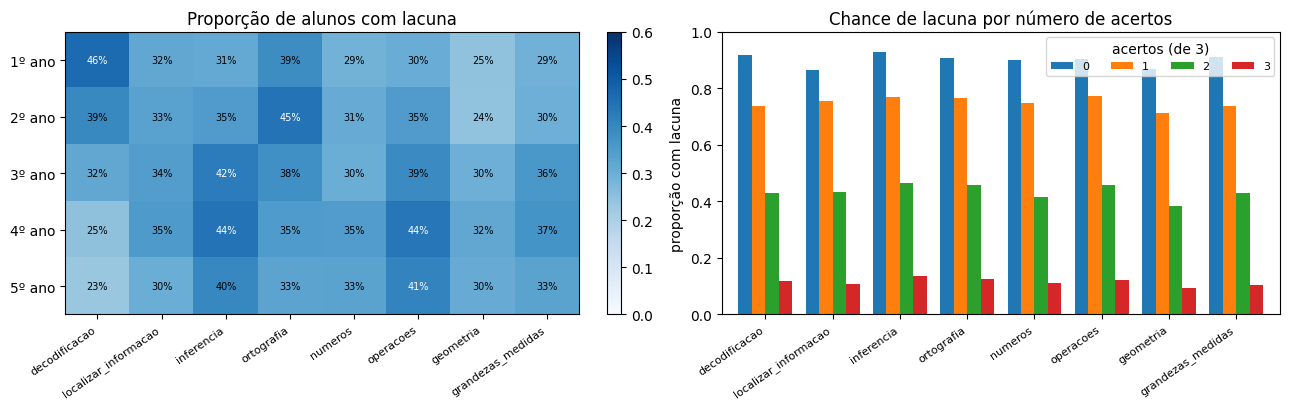

In [38]:
# Junta à tabela dos válidos uma coluna de acertos por conteúdo (o ** desempacota o dicionário em argumentos).
analise = validos.assign(**{c: X[f"acertos_{c}"] for c in CONTEUDOS})
# Título da distribuição abaixo.
print("Lacunas por aluno (de 8):")
# Y.sum(axis=1) soma cada linha: o número de lacunas de cada aluno (0 a 8).
# value_counts(normalize=True) dá a proporção de alunos com cada número de lacunas.
print(pd.Series(Y.sum(axis=1)).value_counts(normalize=True).sort_index().round(3).to_dict(), "\n")

# Chance de ter lacuna conforme o número de acertos no conteúdo
# groupby(c) separa os alunos pelo número de acertos no conteúdo c (0, 1, 2 ou 3);
# a média da coluna de lacuna em cada grupo é a proporção de alunos com lacuna.
chance = pd.DataFrame({c: analise.groupby(c)[f"lacuna_{c}"].mean() for c in CONTEUDOS})
# Os acertos vieram como 0.0, 1.0…; converte para inteiros só para a tabela ficar limpa.
chance.index = chance.index.astype(int)
# Nome do índice, que aparece no cabeçalho da tabela.
chance.index.name = "acertos"
# Título da tabela abaixo.
print("Proporção de alunos com lacuna, por número de acertos no conteúdo (colunas = acertos):")
# .T transpõe a tabela (linhas viram colunas) para caber melhor na tela.
print(chance.T.round(2).to_string(), "\n")

# Lacunas andam juntas? Correlação média entre conteúdos da mesma disciplina e de disciplinas diferentes
# .corr() calcula a correlação de Pearson entre cada par de colunas: de -1 a 1; 0 = sem relação.
corr = pd.DataFrame(Y, columns=CONTEUDOS).corr()
# a < b compara os nomes em ordem alfabética: assim cada par entra uma única vez (e nunca a < a).
mesma = [corr.loc[a, b] for a in CONTEUDOS for b in CONTEUDOS
         if a < b and DISCIPLINA_POR_CONTEUDO[a] == DISCIPLINA_POR_CONTEUDO[b]]
# Mesma ideia, para pares de disciplinas diferentes.
outra = [corr.loc[a, b] for a in CONTEUDOS for b in CONTEUDOS
         if a < b and DISCIPLINA_POR_CONTEUDO[a] != DISCIPLINA_POR_CONTEUDO[b]]
# Média das correlações em cada grupo, com 2 casas decimais.
print(f"Correlação média entre lacunas: mesma disciplina {np.mean(mesma):.2f} | disciplinas diferentes {np.mean(outra):.2f}")

# Uma figura com dois gráficos lado a lado (1 linha, 2 colunas); figsize em polegadas.
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
# Tabela 5 × 8: proporção de lacunas por série (linhas) e conteúdo (colunas).
prevalencia = validos.groupby("serie")[ROTULOS].mean()
# imshow desenha a matriz como mapa de calor; vmin/vmax fixam a escala de cores entre 0% e 60%.
im = ax1.imshow(prevalencia.to_numpy(), cmap="Blues", vmin=0, vmax=0.6, aspect="auto")
# Título e marcações dos eixos (uma por conteúdo e uma por série).
ax1.set(title="Proporção de alunos com lacuna", xticks=range(len(CONTEUDOS)), yticks=range(len(SERIES)),
        yticklabels=[f"{s}º ano" for s in SERIES])
# Nomes dos conteúdos inclinados para não se sobreporem.
ax1.set_xticklabels(CONTEUDOS, rotation=35, ha="right", fontsize=8)
# np.ndenumerate percorre a matriz devolvendo ((linha, coluna), valor): escreve o % em cada quadrado.
for (i, j), v in np.ndenumerate(prevalencia.to_numpy()):
    # Texto branco nos quadrados escuros e preto nos claros, para manter a leitura.
    ax1.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=7, color="white" if v > 0.4 else "black")
# Barra lateral com a escala de cores.
fig.colorbar(im, ax=ax1, fraction=0.03)
# Gráfico de barras: para cada conteúdo, uma barra por número de acertos.
chance.T.plot.bar(ax=ax2, rot=35, width=0.8)
# Título, rótulo do eixo y e escala de 0 a 1 do segundo gráfico.
ax2.set(title="Chance de lacuna por número de acertos", ylabel="proporção com lacuna", ylim=(0, 1))
# Nomes dos conteúdos inclinados no eixo x.
ax2.set_xticklabels(CONTEUDOS, rotation=35, ha="right", fontsize=8)
# Legenda: uma cor para cada número de acertos, em 4 colunas.
ax2.legend(title="acertos (de 3)", fontsize=8, ncol=4)
# Ajusta os espaços para nada ficar cortado e mostra a figura.
fig.tight_layout()
# Exibe a figura no notebook.
plt.show()

**Leitura dos resultados:**
- Cerca de 21% dos alunos não têm nenhuma lacuna e 4% têm lacuna nos 8 conteúdos; a maioria fica no meio. Em cada conteúdo, entre 28% e 39% dos alunos têm lacuna: há menos "sim" do que "não", por isso os modelos usam `class_weight="balanced"`.
- O mapa de calor reproduz o padrão da simulação: no 1º e 2º ano, as lacunas se concentram em decodificação e ortografia; do 3º ano em diante, em inferência e operações.
- **3 questões são pouco:** quem acerta 2 de 3 tem lacuna em cerca de 43% dos casos, e até quem acerta 3 de 3 tem em ~10%. Olhar só os acertos de um conteúdo vai errar muito na fronteira.
- **As lacunas andam juntas:** correlação média de 0,39 entre conteúdos da mesma disciplina e 0,22 entre disciplinas diferentes. É essa informação extra que o modelo pode usar e a regra do corte, não.

## 8. Separação treino/teste por escola
- O **teste** fica guardado e é usado **uma única vez**, no passo 13. Todas as escolhas (modelo, hiperparâmetros, limiar e margem de dúvida) são feitas só com o treino.
- A separação é **por escola** (`StratifiedGroupKFold`): todos os alunos de uma escola ficam de um lado só. O modelo será usado em escolas que nunca viu; misturar alunos da mesma escola nos dois lados deixaria o resultado otimista (**vazamento de dados**).
- O `StratifiedGroupKFold` só sabe estratificar por **um** rótulo, e aqui há 8. Por isso a estratificação usa o **número de lacunas** do aluno (0 a 8): treino e teste ficam com a mesma mistura de alunos com poucas e com muitas lacunas.
- Uma das 5 partes (~20%) vira o teste. A mesma estratégia, com 5 partes, é usada na validação cruzada dentro do treino. As partes da validação cruzada são calculadas **uma vez** (`CV_PARTES`) e reutilizadas em todas as comparações, para que todos os modelos sejam avaliados exatamente nos mesmos alunos.

**Conceitos usados:**
- **Vazamento de dados (data leakage):** quando informação do teste "vaza" para o treino e o modelo parece melhor do que é. Alunos da mesma escola se parecem (mesmo professor, mesma região); se a escola aparece nos dois lados, o teste deixa de medir o desempenho em escolas novas.
- **Validação cruzada (k-fold):** divide o treino em k partes (aqui, 5); treina em 4 e avalia na 5ª, repetindo até cada parte ter sido a de avaliação uma vez. A média das 5 rodadas é mais confiável que uma única divisão.
- **Estratificar:** fazer cada parte ter a mesma proporção de casos que o total.

```
alunos válidos ─┬─ treino (~80%, 47 escolas) ──► validação cruzada em 5 partes: comparar modelos, ajustar, escolher limiar e margem
                └─ teste  (~20%, 13 escolas) ──► usado uma única vez, no passo 13
```

A função `resumo` reúne as métricas do projeto (F1-macro, recall e precisão de lacuna, acurácia) para que todos os passos as calculem do mesmo jeito.

In [39]:
# Número de lacunas de cada aluno (0 a 8). O StratifiedGroupKFold só estratifica por um rótulo,
# então usamos esse resumo para manter a mesma mistura de alunos nas partes.
estrato = Y.sum(axis=1)   # número de lacunas do aluno (0 a 8), usado só para estratificar
# Divide em 5 partes, sem separar alunos da mesma escola (groups), embaralhando com semente fixa.
divisor = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
# .split gera as 5 divisões; next() pega só a primeira: ~80% treino e ~20% teste.
idx_treino, idx_teste = next(divisor.split(X, estrato, groups=grupos))
# .iloc seleciona linhas de um DataFrame pela posição.
X_treino, X_teste = X.iloc[idx_treino], X.iloc[idx_teste]
# Y é um array numpy: a seleção por posição é direta com colchetes.
Y_treino, Y_teste = Y[idx_treino], Y[idx_teste]
# Escolas dos alunos de treino (a validação cruzada também separa por escola).
grupos_treino = grupos[idx_treino]
# isdisjoint: True se os dois conjuntos não têm nada em comum, ou seja, nenhuma escola nos dois lados.
assert set(grupos_treino).isdisjoint(grupos[idx_teste]), "uma escola apareceu no treino e no teste"

# Partes da validação cruzada (por escola), calculadas uma vez e reutilizadas
# list(...) guarda as 5 divisões do treino, para todos os modelos serem avaliados nos mesmos alunos.
CV_PARTES = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
                 .split(X_treino, estrato[idx_treino], groups=grupos_treino))
# Confere a mesma regra dentro do treino: nenhuma escola dos dois lados em nenhuma das 5 partes.
for parte_treino, parte_valid in CV_PARTES:
    # Nenhuma escola pode estar ao mesmo tempo na parte de treino e na de validação.
    assert set(grupos_treino[parte_treino]).isdisjoint(grupos_treino[parte_valid])

# Métricas multirrótulo: calculadas em cada conteúdo e depois com média simples entre os 8
# Nomes que o scikit-learn entende; "macro" = média simples entre os conteúdos.
METRICAS = {"f1_macro": "f1_macro", "recall_lacuna": "recall_macro"}


def resumo(Y_real, Y_previsto) -> dict:
    """As métricas do projeto para uma previsão sim/não por conteúdo (usada nos passos 9, 12 e 13)."""
    # zero_division=0: se não houver nenhuma previsão "lacuna", a precisão vale 0 em vez de aviso.
    return {"f1_macro": f1_score(Y_real, Y_previsto, average="macro", zero_division=0),
            "recall_lacuna": recall_score(Y_real, Y_previsto, average="macro", zero_division=0),
            "precisao_lacuna": precision_score(Y_real, Y_previsto, average="macro", zero_division=0),
            # Proporção de células (aluno × conteúdo) em que a previsão bate com o rótulo.
            "acuracia_por_conteudo": (Y_real == Y_previsto).mean()}


# Tamanho do treino: alunos e escolas distintas.
print(f"Treino: {len(X_treino)} alunos de {len(set(grupos_treino))} escolas")
# Tamanho do teste: alunos e escolas distintas.
print(f"Teste:  {len(X_teste)} alunos de {len(set(grupos[idx_teste]))} escolas")
# Proporção de 1 nos rótulos: precisa ser parecida nos dois lados.
print("Proporção de lacunas (treino | teste):", Y_treino.mean().round(3), "|", Y_teste.mean().round(3))

Treino: 6214 alunos de 47 escolas
Teste:  1640 alunos de 13 escolas
Proporção de lacunas (treino | teste): 0.342 | 0.334


## 9. Baselines
Um modelo só se justifica se superar soluções simples. Usamos duas réguas:
- **Dummy:** responde sempre a classe mais frequente de cada conteúdo, ou seja, "sem lacuna" em tudo.
- **Regra do corte:** aponta lacuna quando o aluno acerta **menos de N** das 3 questões do conteúdo. É o que um professor faria olhando a correção. O corte `N` (1, 2 ou 3) é escolhido **no treino**, pelo maior F1-macro, para a régua ser a melhor regra possível desse tipo.

Elas são avaliadas no teste junto com o modelo, no passo 13.

**Conceito: baseline.** É a referência mínima de desempenho. Se o modelo não superar uma regra que qualquer pessoa aplicaria à mão, ele só acrescenta complexidade. O Dummy mostra o outro extremo: um "modelo" que nunca encontra lacuna pode ter acurácia alta só porque a maioria dos alunos não tem lacuna.

In [40]:
def regra_corte(X_: pd.DataFrame, corte: int) -> np.ndarray:
    """Lacuna (1) quando o aluno acerta menos de `corte` questões do conteúdo."""
    # Compara cada célula de acertos com o corte e converte True/False em 1/0.
    return (X_[COLUNAS_ACERTOS].to_numpy() < corte).astype(int)


# Testa os cortes possíveis (1, 2 e 3) no treino e guarda o F1-macro de cada um.
f1_por_corte = {corte: resumo(Y_treino, regra_corte(X_treino, corte))["f1_macro"] for corte in (1, 2, 3)}
# max com key=dicionario.get devolve a CHAVE (o corte) que tem o maior valor (o maior F1).
CORTE_REGRA = max(f1_por_corte, key=f1_por_corte.get)
# O Dummy "aprende" só qual é a resposta mais frequente em cada conteúdo ("sem lacuna").
dummy = DummyClassifier(strategy="most_frequent").fit(X_treino, Y_treino)
# F1 de cada corte, arredondado para 3 casas.
print("F1-macro da regra no treino, por corte:", {k: round(v, 3) for k, v in f1_por_corte.items()})
# O corte vencedor, por extenso.
print(f"Corte escolhido: lacuna quando acerta menos de {CORTE_REGRA} de {QUESTOES_POR_CONTEUDO}")

F1-macro da regra no treino, por corte: {1: 0.229, 2: 0.596, 3: 0.686}
Corte escolhido: lacuna quando acerta menos de 3 de 3


## 10. Modelos candidatos e validação cruzada
Cada aluno tem **8 respostas sim/não** (uma por conteúdo). A estratégia usada é a **um-contra-o-resto** (`OneVsRestClassifier`): um classificador binário por conteúdo, todos recebendo **as 13 features**. Assim, para decidir se há lacuna em inferência, o modelo também olha localizar informação, decodificação, a série etc.

| Modelo | Como funciona | Por que testar |
|---|---|---|
| Regressão logística | soma ponderada das features (cada feature tem um peso), transformada em probabilidade pela função sigmoide | simples, explicável (dá para ler os pesos), probabilidades em geral bem calibradas |
| Random Forest | centenas de árvores de decisão, cada uma treinada numa amostra diferente; a resposta é a média dos votos | capta combinações entre conteúdos e série sem ajuste fino |
| Gradient Boosting | árvores construídas em sequência, cada uma corrigindo os erros das anteriores | costuma ser o mais preciso em dados de tabela |

**Conceitos usados:**
- **Sigmoide:** a função `1 / (1 + e^(-z))`, que transforma qualquer número `z` num valor entre 0 e 1, interpretado como probabilidade.
- **Padronização (`StandardScaler`):** deixa cada feature com média 0 e desvio-padrão 1. A regressão logística precisa disso para que os pesos sejam comparáveis; as árvores não precisam. Fica **dentro do `Pipeline`** para ser ajustada só com os dados de treino de cada rodada (senão, haveria vazamento).
- **`class_weight="balanced"`:** como há menos alunos com lacuna do que sem, os erros na lacuna recebem peso maior no treino, o que favorece o recall.

A comparação é por **validação cruzada agrupada por escola, só no treino**. Critério: maior **F1-macro**; se a diferença para um modelo mais simples for menor que 0,005, fica o mais simples. O recall de lacuna é acompanhado ao lado.

> Alternativa considerada: `MultiOutputClassifier`, que também treina um modelo por conteúdo. O resultado é o mesmo, mas a exportação para ONNX entrega as probabilidades como uma **lista de 8 matrizes**, mais difícil de ler no Java; o `OneVsRestClassifier` entrega uma matriz única `[N, 8]`.

In [41]:
# Os três candidatos, todos embrulhados para o caso multirrótulo (um classificador por conteúdo).
CANDIDATOS = {   # do mais simples ao mais complexo
    # Pipeline: primeiro padroniza (média 0, desvio 1), depois a regressão logística.
    # O padronizador é ajustado só nos dados de treino de cada rodada, o que evita vazamento.
    # class_weight="balanced": erros na classe menos frequente (lacuna) pesam mais no treino.
    # max_iter=1000: permite mais iterações para o otimizador convergir.
    "Regressão logística": make_pipeline(
        StandardScaler(), OneVsRestClassifier(LogisticRegression(class_weight="balanced", max_iter=1000))),
    # 300 árvores de decisão votando; min_samples_leaf=5 impede folhas com poucos alunos (sobreajuste).
    # random_state fixa o sorteio interno; n_jobs=-1 usa todos os núcleos do processador.
    "Random Forest": OneVsRestClassifier(RandomForestClassifier(
        n_estimators=300, min_samples_leaf=5, class_weight="balanced", random_state=SEED, n_jobs=-1)),
    # Árvores construídas em sequência, cada uma corrigindo os erros da anterior.
    "Gradient Boosting": OneVsRestClassifier(HistGradientBoostingClassifier(
        class_weight="balanced", random_state=SEED)),
}
# Dicionário que vai guardar os resultados de cada modelo.
linhas = {}
for nome, candidato in CANDIDATOS.items():
    # Validação cruzada: treina em 4 partes e avalia na 5ª, 5 vezes, sempre só com o treino.
    r = cross_validate(candidato, X_treino, Y_treino, cv=CV_PARTES, scoring=METRICAS)
    # Média e desvio-padrão das 5 rodadas. O desvio mostra o quanto o resultado oscila.
    linhas[nome] = {"f1_macro": r["test_f1_macro"].mean(), "f1_desvio": r["test_f1_macro"].std(),
                    "recall_lacuna": r["test_recall_lacuna"].mean()}
# Tabela de comparação; .T põe um modelo por linha.
tabela_cv = pd.DataFrame(linhas).T
# Regra de desempate: o PRIMEIRO da lista (o mais simples) que fique a menos de 0,005 do melhor F1-macro.
NOME_MODELO = next(n for n in CANDIDATOS if tabela_cv.loc[n, "f1_macro"] >= tabela_cv["f1_macro"].max() - 0.005)
# Tabela da validação cruzada.
print(tabela_cv.round(3))
# \n no começo do texto pula uma linha antes.
print("\nModelo escolhido:", NOME_MODELO)

                     f1_macro  f1_desvio  recall_lacuna
Regressão logística     0.722      0.008          0.774
Random Forest           0.717      0.008          0.781
Gradient Boosting       0.708      0.009          0.757

Modelo escolhido: Regressão logística


**Leitura dos resultados:** regressão logística (0,722) e Random Forest (0,717) **empataram**: a diferença é menor que o desvio entre as rodadas. O Gradient Boosting ficou um pouco atrás (0,708). Pela regra de desempate, fica a **regressão logística**, a mais simples, leve e explicável. O resultado faz sentido: a relação entre acertos e lacuna é quase linear (mais acertos → menos chance de lacuna), e os modelos de árvore não têm padrão extra para explorar.

## 11. Ajuste de hiperparâmetros
O modelo escolhido passa por uma busca em grade (`GridSearchCV`), com **as mesmas partes da validação cruzada**, só no treino. A grade é pequena de propósito: o objetivo é confirmar que a configuração padrão não está longe do ideal, sem "decorar" a validação. No fim, a busca retreina o melhor modelo com todo o treino (`refit`).

**Conceitos usados:**
- **Parâmetro × hiperparâmetro:** parâmetros são aprendidos no treino (os pesos da regressão logística); hiperparâmetros são escolhidos antes do treino (por exemplo, `C`).
- **Regularização (`C`):** penaliza pesos muito grandes, para o modelo não se ajustar demais aos detalhes do treino (**sobreajuste**). `C` pequeno = regularização forte (modelo mais contido); `C` grande = regularização fraca.
- **Busca em grade:** testa todas as combinações de uma lista de valores e fica com a de melhor métrica na validação cruzada.

In [42]:
# Valores de hiperparâmetros a testar para cada modelo (só o escolhido no passo 10 é usado).
# Nomes com "__" indicam o caminho dentro dos objetos: etapa__estimador__parâmetro.
GRADES = {
    # C controla a regularização: C pequeno = modelo mais "contido"; C grande = mais livre.
    "Regressão logística": {"onevsrestclassifier__estimator__C": [0.01, 0.1, 1.0, 10.0]},
    "Random Forest": {"estimator__min_samples_leaf": [1, 5, 20], "estimator__max_features": ["sqrt", None]},
    "Gradient Boosting": {"estimator__learning_rate": [0.03, 0.1], "estimator__max_depth": [3, None]},
}
# GridSearchCV testa todas as combinações da grade com a mesma validação cruzada e escolhe a de maior F1-macro.
# clone(...) parte de uma cópia sem treino do candidato escolhido.
busca = GridSearchCV(clone(CANDIDATOS[NOME_MODELO]), GRADES[NOME_MODELO], cv=CV_PARTES, scoring="f1_macro")
# Executa a busca; no fim, retreina o melhor com todo o treino (refit, ligado por padrão).
busca.fit(X_treino, Y_treino)
# O modelo final, já treinado com todo o conjunto de treino.
modelo = busca.best_estimator_
# Combinação vencedora da grade.
print("Melhores hiperparâmetros:", busca.best_params_)
# Compara o F1 depois e antes do ajuste.
print(f"F1-macro na validação cruzada: {busca.best_score_:.3f} (antes do ajuste: {tabela_cv.loc[NOME_MODELO, 'f1_macro']:.3f})")

Melhores hiperparâmetros: {'onevsrestclassifier__estimator__C': 1.0}
F1-macro na validação cruzada: 0.722 (antes do ajuste: 0.722)


**Leitura:** o melhor valor encontrado foi `C = 1.0`, que já é o padrão. O ajuste confirma a configuração inicial; o modelo não depende de uma escolha fina de hiperparâmetros.